**Imports**

In [1]:
import pandas as pd
import numpy as np
import os
import joblib
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All imports successful")

All imports successful


**Load your cleaned dataset**

In [2]:
DATA_PATH = r"C:\Users\Marvella\YEAR 3\FYP\FYP System\data\animal_disease_merged_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Species: {df['Species'].nunique()} unique")
print(f"Diseases: {df['Disease_Prediction'].nunique()} unique")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"\nTop 5 diseases:")
print(df['Disease_Prediction'].value_counts().head())

Dataset loaded: 59,315 rows × 30 columns
Species: 16 unique
Diseases: 162 unique
Missing values: 0

Top 5 diseases:
Disease_Prediction
Parasitic Infestation    8941
Septicemia               8932
Bacterial Pneumonia      6722
Viral Infection          1916
Gastroenteritis           760
Name: count, dtype: int64


**Understand class imbalance**


Most common disease:  Parasitic Infestation (8,941 cases)
Least common disease: Canine Infectious Hepatitis (1 case)
Imbalance ratio: 8941:1


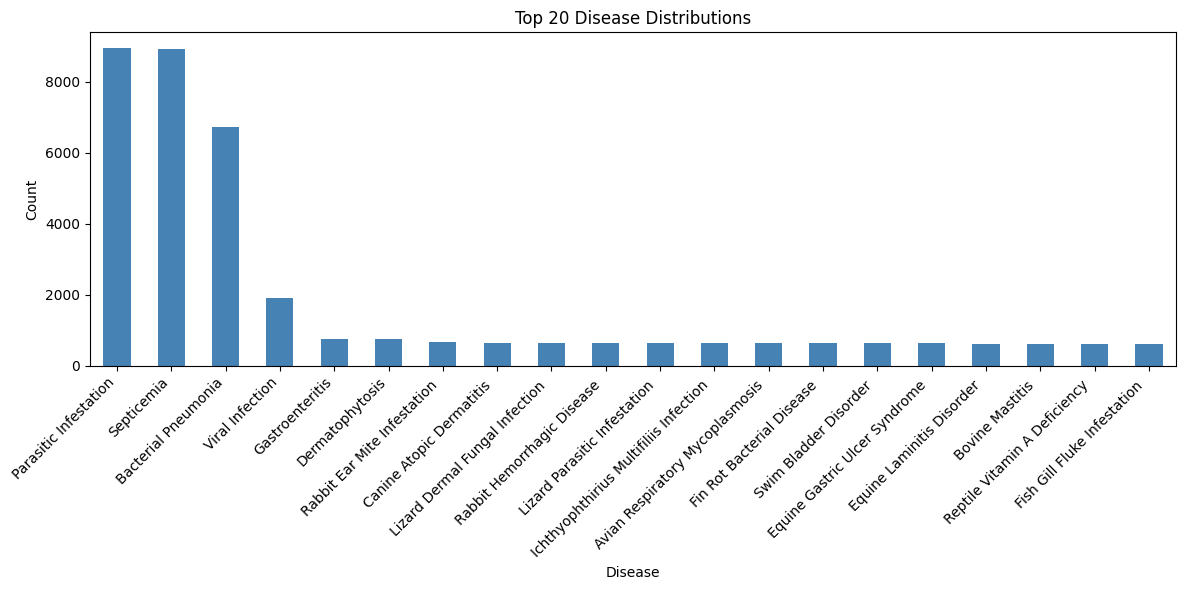

In [3]:
counts = df['Disease_Prediction'].value_counts()
print(f"\nMost common disease:  {counts.index[0]} ({counts.iloc[0]:,} cases)")
print(f"Least common disease: {counts.index[-1]} ({counts.iloc[-1]} case)")
print(f"Imbalance ratio: {counts.iloc[0]}:{counts.iloc[-1]}")

# Plot top 20
plt.figure(figsize=(12, 6))
counts.head(20).plot(kind='bar', color='steelblue')
plt.title('Top 20 Disease Distributions')
plt.xlabel('Disease')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Build symptom text strings**

In [4]:
def build_symptom_text(row):
    """
    Convert a DataFrame row into a natural language symptom description.
    Uses the binary symptom flags that exist after preprocessing.
    """
    # Binary symptom flags (all are 0/1 integers)
    binary_symptoms = {
        'Appetite_Loss':      'appetite loss',
        'Vomiting':           'vomiting',
        'Diarrhea':           'diarrhea',
        'Coughing':           'coughing',
        'Labored_Breathing':  'labored breathing',
        'Lameness':           'lameness',
        'Skin_Lesions':       'skin lesions',
        'Nasal_Discharge':    'nasal discharge',
        'Eye_Discharge':      'eye discharge',
    }
    
    # Only include columns that actually exist in the dataset
    present_labels = []
    absent_labels = []
    for col, label in binary_symptoms.items():
        if col in row.index:
            val = row.get(col, 0)
            if val == 1:
                present_labels.append(label)
            elif val == 0:
                absent_labels.append(label)
    
    present_str = ', '.join(present_labels) if present_labels else 'none'
    absent_str  = ', '.join(absent_labels)  if absent_labels  else 'none'
    
    # Optional: if you have a primary symptom column (you don't), skip it
    # Instead, we'll just list all present symptoms as primary
    primary_symptom = present_labels[0] if present_labels else 'unknown'
    additional = ', '.join(present_labels[1:]) if len(present_labels) > 1 else 'none'
    
    # Safely handle missing columns with .get()
    text = (
        f"Species: {row.get('Species', 'unknown')}. "
        f"Breed: {row.get('Breed', 'unknown')}. "
        f"Age: {row.get('Age', 'unknown')} years. "
        f"Gender: {row.get('Gender', 'unknown')}. "
        f"Weight: {row.get('Weight', 'unknown')} kg. "
        f"Primary symptom: {primary_symptom}. "
        f"Additional symptoms: {additional}. "
        f"Symptoms present: {present_str}. "
        f"Symptoms absent: {absent_str}. "
        f"Body temperature: {row.get('Body_Temperature', 'unknown')} C. "
        f"Danger level: {row.get('Danger_Level_Category', 'unknown')}."
    )
    # Note: Duration and Heart_Rate are not in your preprocessed dataset.
    # If they exist in raw data, you would need to add them to preprocessing.
    return text

# Apply to full dataset
print("Building symptom text strings...")
df['symptom_text'] = df.apply(build_symptom_text, axis=1)

# Verify a few examples
print("\n--- EXAMPLE TEXT STRINGS ---")
for i in [0, 1, 2]:
    print(f"\nRow {i} (Disease: {df['Disease_Prediction'].iloc[i]}):")
    print(df['symptom_text'].iloc[i])

Building symptom text strings...

--- EXAMPLE TEXT STRINGS ---

Row 0 (Disease: Foot and Mouth Disease):
Species: Cow. Breed: Holstein. Age: 3 years. Gender: Female. Weight: 600.0 kg. Primary symptom: appetite loss. Additional symptoms: coughing, labored breathing, nasal discharge. Symptoms present: appetite loss, coughing, labored breathing, nasal discharge. Symptoms absent: vomiting, diarrhea, lameness, skin lesions, eye discharge. Body temperature: 40.1 C. Danger level: High.

Row 1 (Disease: Gastroenteritis):
Species: Dog. Breed: Beagle. Age: 1 years. Gender: Male. Weight: 10.0 kg. Primary symptom: appetite loss. Additional symptoms: vomiting, diarrhea. Symptoms present: appetite loss, vomiting, diarrhea. Symptoms absent: coughing, labored breathing, lameness, skin lesions, nasal discharge, eye discharge. Body temperature: 39.2 C. Danger level: Moderate.

Row 2 (Disease: Equine Influenza):
Species: Horse. Breed: Thoroughbred. Age: 6 years. Gender: Female. Weight: 500.0 kg. Primary 

**Encode target labels**

In [5]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['Disease_Prediction'])

print(f"\nLabel encoding complete.")
print(f"Number of classes: {len(le.classes_)}")
print(f"Example mappings:")
for i in range(min(5, len(le.classes_))):
    print(f"  {le.classes_[i]} → {i}")

# Save encoder for later use (dashboard)
os.makedirs('../models/saved_models', exist_ok=True)
joblib.dump(le, '../models/saved_models/label_encoder.pkl')
print("\nLabel encoder saved to models/saved_models/label_encoder.pkl")


Label encoding complete.
Number of classes: 162
Example mappings:
  Actinobacillus Pleuropneumonia → 0
  Actinobacillus Suis → 1
  African Swine Fever → 2
  Avian Aspergillosis  → 3
  Avian Influenza Infection  → 4

Label encoder saved to models/saved_models/label_encoder.pkl


**Feature Selection**

In [6]:
# List ALL columns that should be used as input features.
# These must exist in your cleaned dataset.
feature_columns = [
    'symptom_text',           # the text we just built
    'Species', 'Breed', 'Age', 'Gender', 'Weight',
    'Appetite_Loss', 'Vomiting', 'Diarrhea', 'Coughing',
    'Labored_Breathing', 'Lameness', 'Skin_Lesions',
    'Nasal_Discharge', 'Eye_Discharge', 'Body_Temperature',
    'Symptom_Count', 'Temp_Risk', 'Symptom_Risk',
    'Critical_Risk', 'Dangerous_Level', 'Danger_Level_Category'
]

# Keep only those that actually exist in df
existing_features = [col for col in feature_columns if col in df.columns]
missing = set(feature_columns) - set(existing_features)
if missing:
    print(f"\n⚠️ Warning: These columns are missing and will be skipped: {missing}")

X = df[existing_features]
y = df['label']
y_names = df['Disease_Prediction']

print(f"\nUsing {len(existing_features)} feature columns (including symptom_text).")


Using 22 feature columns (including symptom_text).


**Stratified train / val / test split**

In [7]:
# Handle rare classes (only 1 sample) – they must stay in training
rare_mask = y_names.map(y_names.value_counts()) == 1
rare_df   = df[rare_mask]
split_df  = df[~rare_mask]

X_split = split_df[existing_features]
y_split = split_df['label']

# Step 1: 85% train+val, 15% test
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
for train_val_idx, test_idx in sss1.split(X_split, y_split):
    X_tv  = X_split.iloc[train_val_idx]
    X_test_split = X_split.iloc[test_idx]
    y_tv  = y_split.iloc[train_val_idx]
    y_test_split = y_split.iloc[test_idx]

# Step 2: From 85%, take 17.6% as validation (approx 15% of total)
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.176, random_state=RANDOM_STATE)
for train_idx, val_idx in sss2.split(X_tv, y_tv):
    X_train_split = X_tv.iloc[train_idx]
    X_val_split   = X_tv.iloc[val_idx]
    y_train_split = y_tv.iloc[train_idx]
    y_val_split   = y_tv.iloc[val_idx]

# Add rare cases to training set
X_rare = rare_df[existing_features]
y_rare = rare_df['label']

X_train_final = pd.concat([X_train_split, X_rare], ignore_index=True)
y_train_final = pd.concat([y_train_split, y_rare], ignore_index=True)
X_val_final   = X_val_split
y_val_final   = y_val_split
X_test_final  = X_test_split
y_test_final  = y_test_split

print(f"\nSplit complete:")
print(f"  Train:      {len(X_train_final):,} rows ({len(X_train_final)/len(df)*100:.1f}%)")
print(f"  Validation: {len(X_val_final):,}  rows ({len(X_val_final)/len(df)*100:.1f}%)")
print(f"  Test:       {len(X_test_final):,}  rows ({len(X_test_final)/len(df)*100:.1f}%)")

train_diseases = y_train_final.nunique()
print(f"\n  Diseases in train: {train_diseases}")
print(f"  Diseases in val:   {y_val_final.nunique()}")
print(f"  Diseases in test:  {y_test_final.nunique()}")


Split complete:
  Train:      41,555 rows (70.1%)
  Validation: 8,868  rows (15.0%)
  Test:       8,892  rows (15.0%)

  Diseases in train: 162
  Diseases in val:   95
  Diseases in test:  95


**Save splits to disk**

In [8]:
os.makedirs('../data/splits', exist_ok=True)

X_train_final.to_csv('../data/splits/X_train.csv', index=False)
X_val_final.to_csv('../data/splits/X_val.csv',     index=False)
X_test_final.to_csv('../data/splits/X_test.csv',   index=False)

y_train_final.to_csv('../data/splits/y_train.csv', index=False)
y_val_final.to_csv('../data/splits/y_val.csv',     index=False)
y_test_final.to_csv('../data/splits/y_test.csv',   index=False)

print("\nAll splits saved to data/splits/")


All splits saved to data/splits/
